# FreshHarvest Transfer Learning with ResNet50

This notebook documents the final cost-conscious model. A pretrained ResNet50 backbone is frozen and only a small 16-class classification head is trained.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt

ARTIFACTS = Path('artifacts')
fast = json.loads((ARTIFACTS / 'transfer' / 'transfer_metrics.json').read_text())
tuned = json.loads((ARTIFACTS / 'transfer-tuned' / 'transfer_metrics.json').read_text())

## Why transfer learning?

The pretrained backbone already contains reusable visual features. Freezing it leaves only 32,784 trainable parameters, reducing training time and compute cost while retaining strong accuracy.

In [2]:
comparison = [
    {
        'run': 'Fast head', 'learning_rate': 1e-3, 'dropout': 0.20,
        'epoch_1_validation': fast['history'][0]['val_accuracy'],
        'best_validation': fast['best_validation_accuracy'],
        'test_accuracy': fast['test_class_accuracy'],
    },
    {
        'run': 'Tuned head', 'learning_rate': tuned['learning_rate'],
        'dropout': tuned['dropout'],
        'epoch_1_validation': tuned['history'][0]['val_accuracy'],
        'best_validation': tuned['best_validation_accuracy'],
        'test_accuracy': tuned['test_class_accuracy'],
    },
]
comparison

[{'run': 'Fast head',
  'learning_rate': 0.001,
  'dropout': 0.2,
  'epoch_1_validation': 0.97875,
  'best_validation': 0.9933333333333333,
  'test_accuracy': 0.9883333333333333},
 {'run': 'Tuned head',
  'learning_rate': 0.0005,
  'dropout': 0.35,
  'epoch_1_validation': 0.96125,
  'best_validation': 0.98375,
  'test_accuracy': 0.9804166666666667}]

## Training and validation accuracy

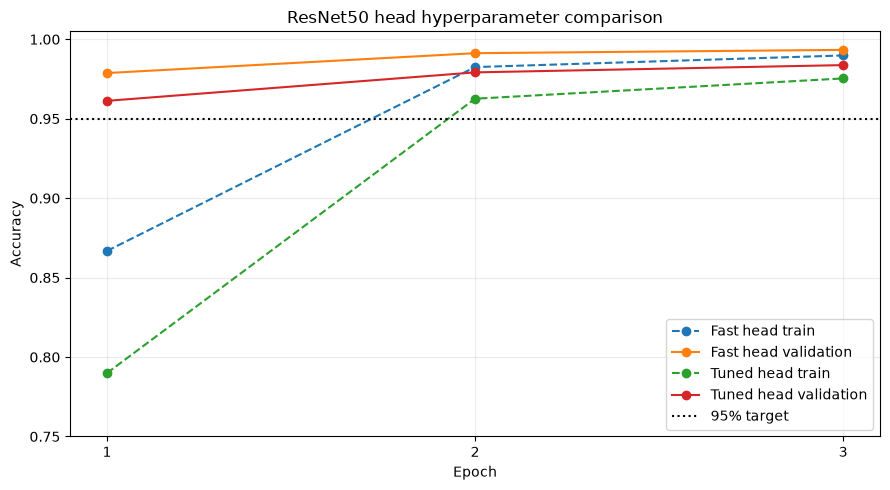

In [3]:
plt.figure(figsize=(9, 5))
for label, result in [('Fast head', fast), ('Tuned head', tuned)]:
    epochs = [row['epoch'] for row in result['history']]
    plt.plot(epochs, [row['train_accuracy'] for row in result['history']], '--o', label=f'{label} train')
    plt.plot(epochs, [row['val_accuracy'] for row in result['history']], '-o', label=f'{label} validation')
plt.axhline(0.95, color='black', linestyle=':', label='95% target')
plt.xticks([1, 2, 3])
plt.ylim(0.75, 1.005)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('ResNet50 head hyperparameter comparison')
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

## Model-selection conclusion

The fast head crossed 95% validation accuracy in epoch 1 and produced the strongest final validation and test scores. There is no meaningful overfitting in the three-epoch curves: validation accuracy remains close to training accuracy and continues to improve. The saved `best_resnet50_model.pt` checkpoint is therefore the selected deployment candidate.

Regularization and optimization used: pretrained batch-normalized backbone, dropout, AdamW weight decay, validation-based checkpointing, and early-stopping logic. Early stopping did not trigger because validation accuracy improved in every epoch.

In [4]:
{
    'selected_model': 'ResNet50 transfer learning',
    'epochs_to_exceed_95_percent': 1,
    'best_validation_accuracy': fast['best_validation_accuracy'],
    'test_16_class_accuracy': fast['test_class_accuracy'],
    'test_fresh_spoiled_accuracy': fast['test_freshness_accuracy'],
    'saved_model': str(ARTIFACTS / 'transfer' / 'best_resnet50_model.pt'),
}

{'selected_model': 'ResNet50 transfer learning',
 'epochs_to_exceed_95_percent': 1,
 'best_validation_accuracy': 0.9933333333333333,
 'test_16_class_accuracy': 0.9883333333333333,
 'test_fresh_spoiled_accuracy': 0.9925,
 'saved_model': 'artifacts\\transfer\\best_resnet50_model.pt'}